# RetailPulse — Customer Segmentation

## Objective

The objective of this notebook is to segment customers based on their purchasing behavior using RFM analysis and unsupervised machine learning.

RFM represents:

- **Recency** — How recently a customer purchased
- **Frequency** — How often a customer purchased
- **Monetary** — How much a customer spent

The analysis will include:

1. Loading cleaned sales data
2. Preparing customer-level transaction data
3. Creating RFM features
4. Exploring RFM distributions
5. Handling skewness and outliers
6. Creating RFM scores
7. Creating interpretable customer segments
8. Preparing features for clustering
9. Applying clustering
10. Profiling and interpreting customer segments

#Importing Libraries 

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

In [2]:
sales_df = pd.read_parquet("../data/processed/clean_sales.parquet")
sales_df.head()

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue,description_clean
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,83.4,15CM CHRISTMAS GLASS BALL 20 LIGHTS
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0,PINK CHERRY LIGHTS
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0,WHITE CHERRY LIGHTS
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,100.8,"RECORD FRAME 7"" SINGLE SIZE"
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,30.0,STRAWBERRY CERAMIC TRINKET BOX


In [3]:
sales_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1007913 entries, 0 to 1007912
Data columns (total 11 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   invoice            1007913 non-null  string        
 1   stock_code         1007913 non-null  string        
 2   description        1007913 non-null  string        
 3   quantity           1007913 non-null  int64         
 4   invoice_date       1007913 non-null  datetime64[us]
 5   unit_price         1007913 non-null  float64       
 6   customer_id        779425 non-null   Int64         
 7   country            1007913 non-null  string        
 8   is_cancelled       1007913 non-null  bool          
 9   revenue            1007913 non-null  float64       
 10  description_clean  1007913 non-null  string        
dtypes: Int64(1), bool(1), datetime64[us](1), float64(2), int64(1), string(5)
memory usage: 153.7 MB


In [4]:
sales_df.shape

(1007913, 11)

In [5]:
sales_df["customer_id"].isna().sum()

np.int64(228488)

In [6]:
sales_df["customer_id"].isna().mean() * 100

np.float64(22.669416904038346)

In [7]:
rfm_data = sales_df.dropna(subset=["customer_id"]).copy()

In [8]:
rfm_data.shape

(779425, 11)

In [9]:
rfm_data.head()

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue,description_clean
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,83.4,15CM CHRISTMAS GLASS BALL 20 LIGHTS
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0,PINK CHERRY LIGHTS
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0,WHITE CHERRY LIGHTS
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,100.8,"RECORD FRAME 7"" SINGLE SIZE"
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,30.0,STRAWBERRY CERAMIC TRINKET BOX


In [10]:
rfm_data["invoice_date"].max()

Timestamp('2011-12-09 12:50:00')

In [11]:
reference_date = pd.Timestamp('2011-12-10 12:50:00')
reference_date

Timestamp('2011-12-10 12:50:00')

In [12]:
rfm = rfm_data.groupby('customer_id').agg(
    Recency=('invoice_date', lambda x: (reference_date - x.max()).days),
    Frequency=('invoice', 'nunique'),
    Monetary=('revenue', 'sum')
).reset_index()

In [13]:
rfm.head()

,customer_id,Recency,Frequency,Monetary
0,12346,326,12,77556.46
1,12347,2,8,4921.53
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40


In [14]:
rfm.shape

(5878, 4)

#RFM Validity

In [15]:
rfm.isna().sum() 

customer_id    0
Recency        0
Frequency      0
Monetary       0
dtype: int64

In [16]:
(rfm[['Recency', 'Frequency', 'Monetary']] < 0).sum()  #recency should never be negative 

Recency      0
Frequency    0
Monetary     0
dtype: int64

In [17]:
(rfm['Frequency'] <= 0).sum()       #frequency should always be positive

np.int64(0)

In [18]:
(rfm['Monetary'] <= 0).sum()              #monetary should always be positive

np.int64(0)

#RFM Distribution

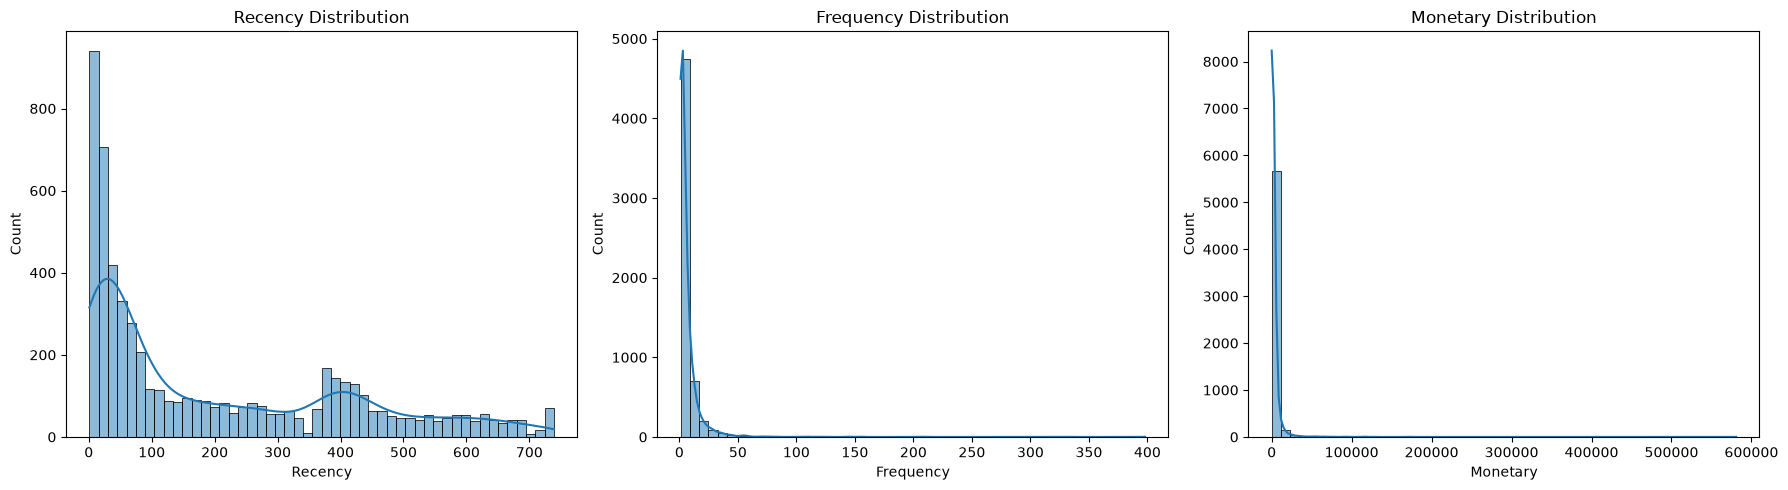

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(rfm['Recency'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Recency Distribution')

sns.histplot(rfm['Frequency'], bins=50, kde=True, ax=axes[1])
axes[1].set_title('Frequency Distribution')

sns.histplot(rfm['Monetary'], bins=50, kde=True, ax=axes[2])
axes[2].set_title('Monetary Distribution')

plt.tight_layout()
plt.show()

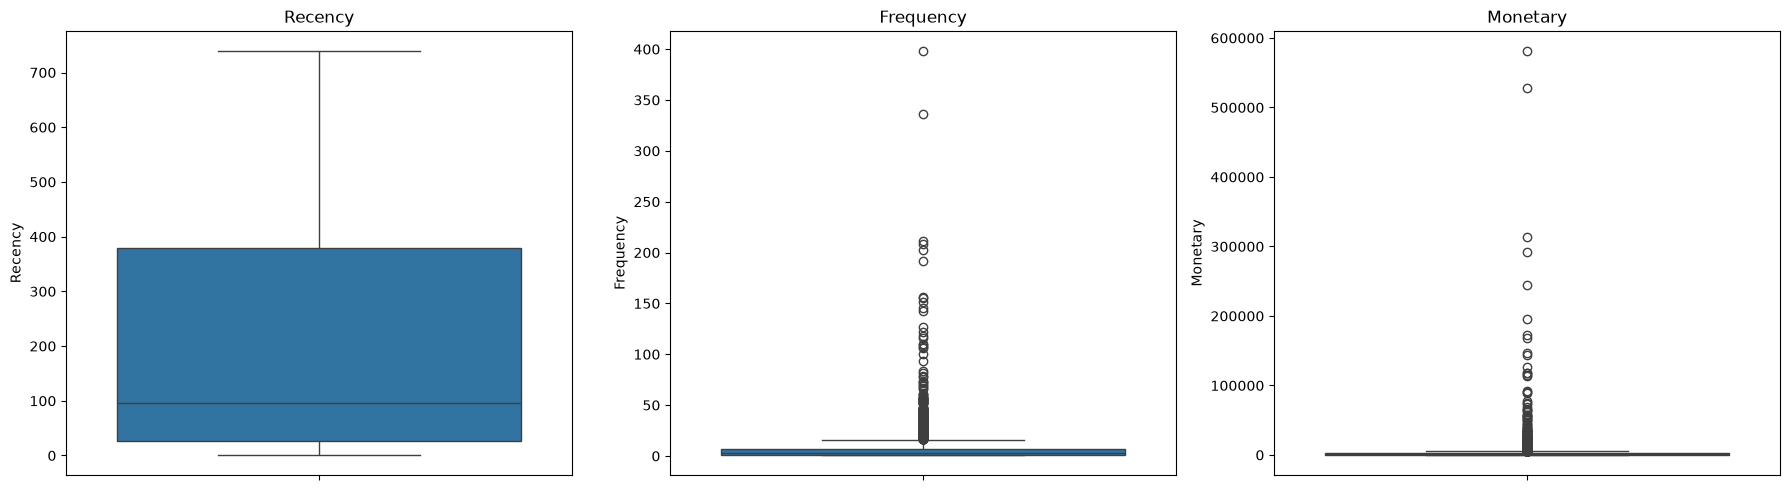

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(y=rfm['Recency'], ax=axes[0])
axes[0].set_title('Recency')

sns.boxplot(y=rfm['Frequency'], ax=axes[1])
axes[1].set_title('Frequency')

sns.boxplot(y=rfm['Monetary'], ax=axes[2])
axes[2].set_title('Monetary')

plt.tight_layout()
plt.show()

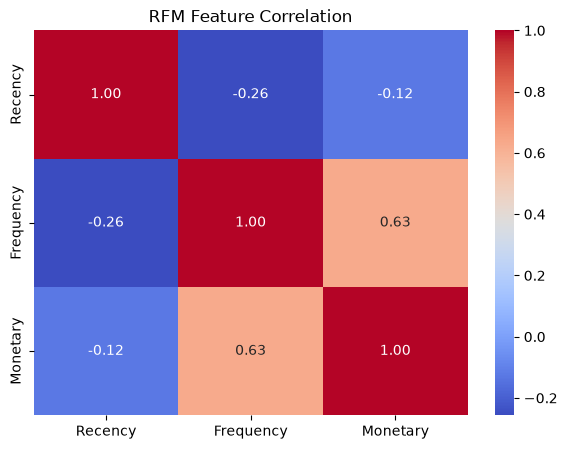

In [21]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    rfm[['Recency', 'Frequency', 'Monetary']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('RFM Feature Correlation')
plt.show()

In [22]:
rfm.to_parquet("../data/processed/customer_rfm.parquet",index=False)

In [23]:
rfm_raw = rfm.copy() 

In [24]:
rfm_log = rfm.copy()

rfm_log['Recency'] = np.log1p(rfm_log['Recency'])
rfm_log['Frequency'] = np.log1p(rfm_log['Frequency'])
rfm_log['Monetary'] = np.log1p(rfm_log['Monetary'])

In [25]:
rfm_log.head()

,customer_id,Recency,Frequency,Monetary
0,12346,5.789960,2.564949,11.258774
1,12347,1.098612,2.197225,8.501578
2,12348,4.330733,1.791759,7.611051
3,12349,2.995732,1.609438,8.396085
4,12350,5.739793,0.693147,5.815324


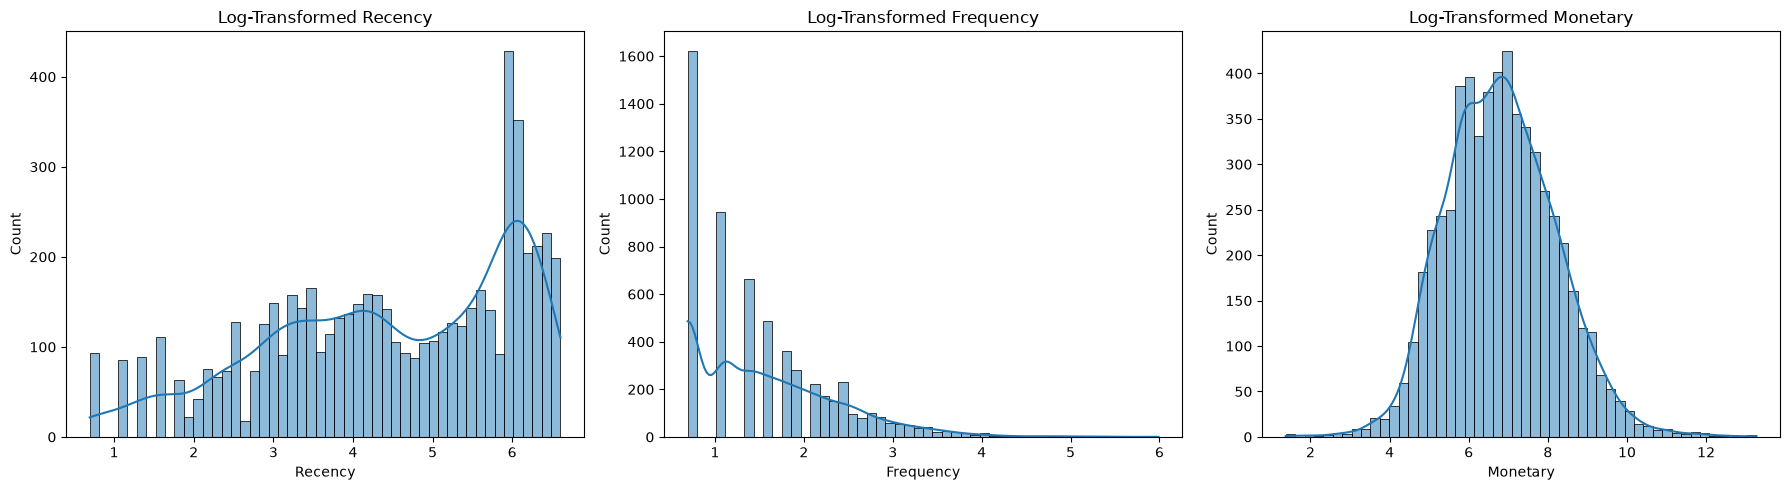

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(rfm_log['Recency'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Log-Transformed Recency')

sns.histplot(rfm_log['Frequency'], bins=50, kde=True, ax=axes[1])
axes[1].set_title('Log-Transformed Frequency')

sns.histplot(rfm_log['Monetary'], bins=50, kde=True, ax=axes[2])
axes[2].set_title('Log-Transformed Monetary')

plt.tight_layout()
plt.show()

In [27]:
rfm_features = rfm_log[['Recency', 'Frequency', 'Monetary']]

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_features)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm_log.index
)

In [28]:
rfm_scaled.describe()

,Recency,Frequency,Monetary
count,5.878000e+03,5.878000e+03,5.878000e+03
mean,-5.052856e-16,2.381370e-16,3.771510e-16
std,1.000085e+00,1.000085e+00,1.000085e+00
min,-2.412014e+00,-1.058146e+00,-3.929108e+00
25%,-7.428435e-01,-1.058146e+00,-7.062613e-01
50%,7.733065e-02,-2.017514e-01,-3.604460e-02
75%,9.547202e-01,6.546432e-01,6.506556e-01
max,1.380464e+00,5.484918e+00,4.659776e+00


## RFM Scoring

Customers are assigned scores from 1 to 5 for each RFM dimension.

- Recency: lower values receive higher scores.
- Frequency: higher values receive higher scores.
- Monetary: higher values receive higher scores.

A score of 5 represents stronger customer performance for that dimension.

In [29]:
rfm_score = rfm_raw.copy()

rfm_score['R_Score'] = pd.qcut(
    rfm_score['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm_score['F_Score'] = pd.qcut(
    rfm_score['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm_score['M_Score'] = pd.qcut(
    rfm_score['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

In [30]:
rfm_score['RFM_Score'] = (
    rfm_score['R_Score'] +
    rfm_score['F_Score'] +
    rfm_score['M_Score']
)

In [31]:
rfm_score['RFM_Score'].describe()

count    5878.000000
mean        9.000000
std         3.641732
min         3.000000
25%         6.000000
50%         9.000000
75%        12.000000
max        15.000000
Name: RFM_Score, dtype: float64

In [32]:
rfm_score.head()

,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,12,77556.46,2,5,5,12
1,12347,2,8,4921.53,5,4,5,14
2,12348,75,5,2019.40,3,4,4,11
3,12349,19,4,4428.69,5,3,5,13
4,12350,310,1,334.40,2,1,2,5


In [33]:
rfm_score['RFM_Score'].value_counts().sort_index()

RFM_Score
3     317
4     490
5     503
6     464
7     475
8     470
9     511
10    451
11    477
12    428
13    439
14    387
15    466
Name: count, dtype: int64

In [34]:
rfm_score.groupby('RFM_Score')[[
    'Recency',
    'Frequency',
    'Monetary'
]].mean()

,Recency,Frequency,Monetary
RFM_Score,,,
3,573.545741,1.000000,144.007666
4,480.106122,1.091837,230.527696
5,364.664016,1.272366,324.573380
6,272.997845,1.562500,453.075433
7,244.128421,2.075789,654.899537
8,199.510638,2.597872,839.836619
9,163.322896,3.403131,1047.830041
10,127.505543,4.059867,1471.666969
11,94.071279,5.467505,1969.839394


## Business-Based Customer Segmentation

Customers are grouped into interpretable behavioral segments using their RFM scores.

The segmentation considers the individual Recency, Frequency, and Monetary scores rather than relying only on the aggregate RFM score.

In [35]:
def assign_segment(row):
    
    R = row['R_Score']
    F = row['F_Score']
    M = row['M_Score']
    
    # Highest-value and highly engaged customers
    if R >= 4 and F >= 4 and M >= 4:
        return 'Champions'
    
    # Recent and frequent customers with strong potential
    elif R >= 4 and F >= 3:
        return 'Loyal Customers'
    
    # Recent customers who have not purchased frequently yet
    elif R >= 4 and F <= 2:
        return 'New / Promising Customers'
    
    # Customers who historically purchased but are becoming inactive
    elif R <= 3 and F >= 3 and M >= 3:
        return 'At Risk'
    
    # Customers with low engagement and low value
    elif R <= 2 and F <= 2 and M <= 2:
        return 'Lost / Hibernating'
    
    else:
        return 'Needs Attention'

In [36]:
rfm_score['Segment'] = rfm_score.apply(assign_segment, axis=1)

In [37]:
segment_counts = rfm_score['Segment'].value_counts()
segment_counts

Segment
At Risk                      1302
Champions                    1289
Lost / Hibernating           1282
Needs Attention               943
Loyal Customers               621
New / Promising Customers     441
Name: count, dtype: int64

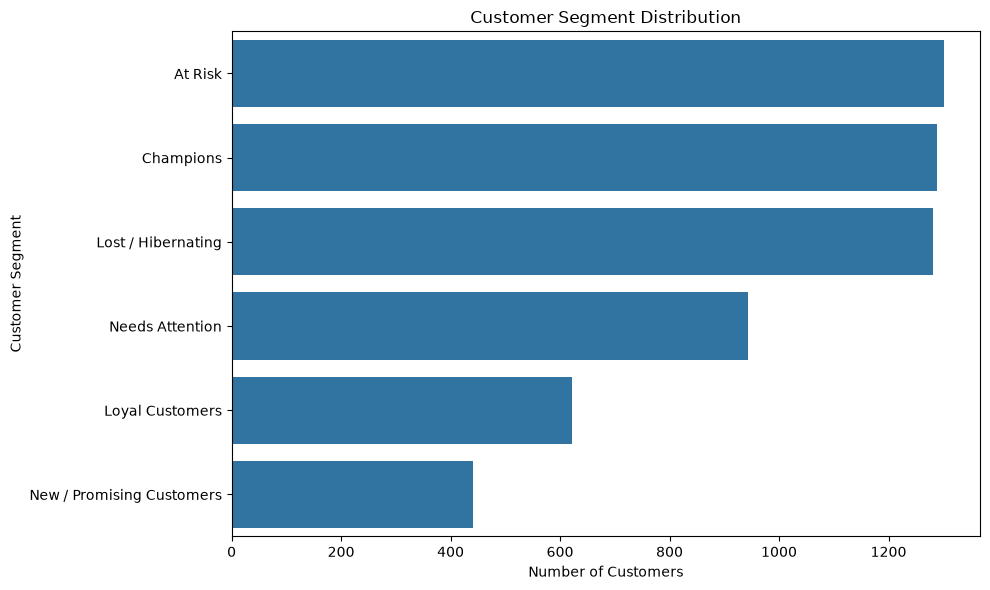

In [38]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=rfm_score,
    y='Segment',
    order=segment_counts.index
)

plt.title('Customer Segment Distribution')
plt.xlabel('Number of Customers')
plt.ylabel('Customer Segment')

plt.tight_layout()
plt.show()

In [39]:
segment_profile = rfm_score.groupby('Segment').agg(
    Customers=('customer_id', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Avg_RFM_Score=('RFM_Score', 'mean')
).sort_values(
    'Avg_RFM_Score',
    ascending=False
)

segment_profile

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_RFM_Score
Segment,,,,,
Champions,1289,19.719162,17.146625,9169.609678,13.910008
Loyal Customers,621,24.235105,3.830918,1033.625380,10.660225
At Risk,1302,226.076037,6.479263,2715.312041,10.084485
New / Promising Customers,441,27.965986,1.460317,888.522132,7.970522
Needs Attention,943,252.095440,2.002121,701.887852,6.681866
Lost / Hibernating,1282,466.888456,1.185647,252.918293,4.216849


In [40]:
segment_profile['Customer_Percentage'] = (
    segment_profile['Customers'] /
    len(rfm_score) * 100
)

segment_profile

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_RFM_Score,Customer_Percentage
Segment,,,,,,
Champions,1289,19.719162,17.146625,9169.609678,13.910008,21.929228
Loyal Customers,621,24.235105,3.830918,1033.625380,10.660225,10.564818
At Risk,1302,226.076037,6.479263,2715.312041,10.084485,22.150391
New / Promising Customers,441,27.965986,1.460317,888.522132,7.970522,7.502552
Needs Attention,943,252.095440,2.002121,701.887852,6.681866,16.042872
Lost / Hibernating,1282,466.888456,1.185647,252.918293,4.216849,21.81014


In [41]:
rfm_score[['R_Score', 'F_Score', 'M_Score']].value_counts().head(20)

R_Score  F_Score  M_Score
5        5        5          466
1        1        1          317
4        5        5          247
1        2        1          172
2        1        1          166
3        4        4          165
1        1        2          152
4        4        4          146
3        5        5          135
1        2        2          135
5        4        4          131
2        2        1          122
                  2          120
         3        3          110
3        3        3          107
4        3        3          104
2        3        2          100
         1        2           98
5        5        4           95
3        1        1           93
Name: count, dtype: int64

## RFM Business Segment Definitions

The business segments are defined using the individual RFM scores:

- **Champions:** High Recency, Frequency, and Monetary scores.
- **Loyal Customers:** Recent customers with relatively high purchase frequency.
- **New / Promising Customers:** Recent customers who have not yet developed a high purchase frequency.
- **At Risk:** Customers with lower Recency scores but relatively strong historical Frequency and Monetary scores.
- **Lost / Hibernating:** Customers with low scores across all RFM dimensions.
- **Needs Attention:** Customers who do not strongly fit the other behavioral categories and may require targeted engagement.

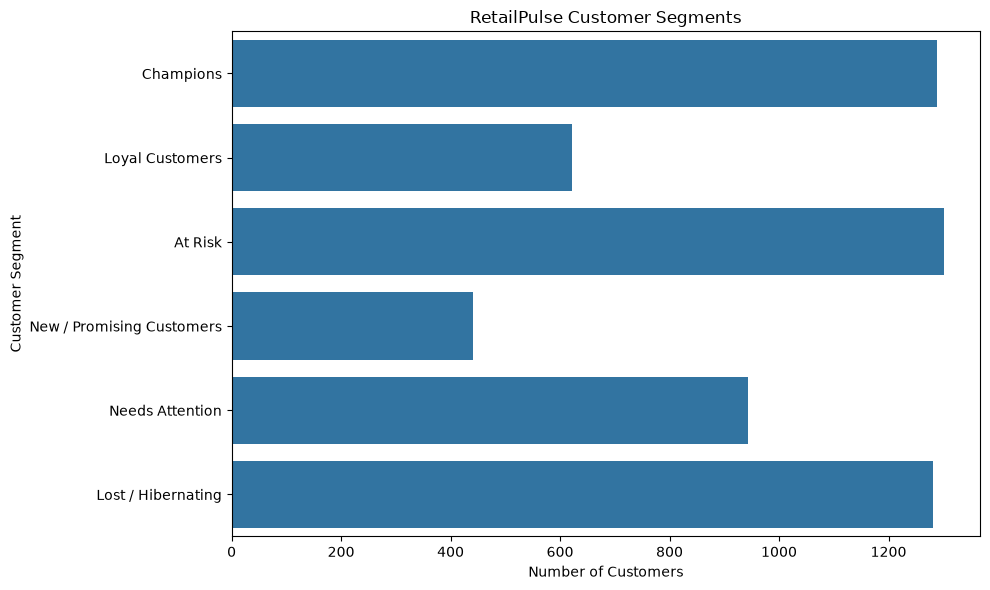

In [42]:
plt.figure(figsize=(10, 6))

segment_order = (
    segment_profile
    .sort_values('Avg_RFM_Score', ascending=False)
    .index
)

sns.barplot(
    data=segment_profile.reset_index(),
    y='Segment',
    x='Customers',
    order=segment_order
)

plt.title('RetailPulse Customer Segments')
plt.xlabel('Number of Customers')
plt.ylabel('Customer Segment')

plt.tight_layout()
plt.show()

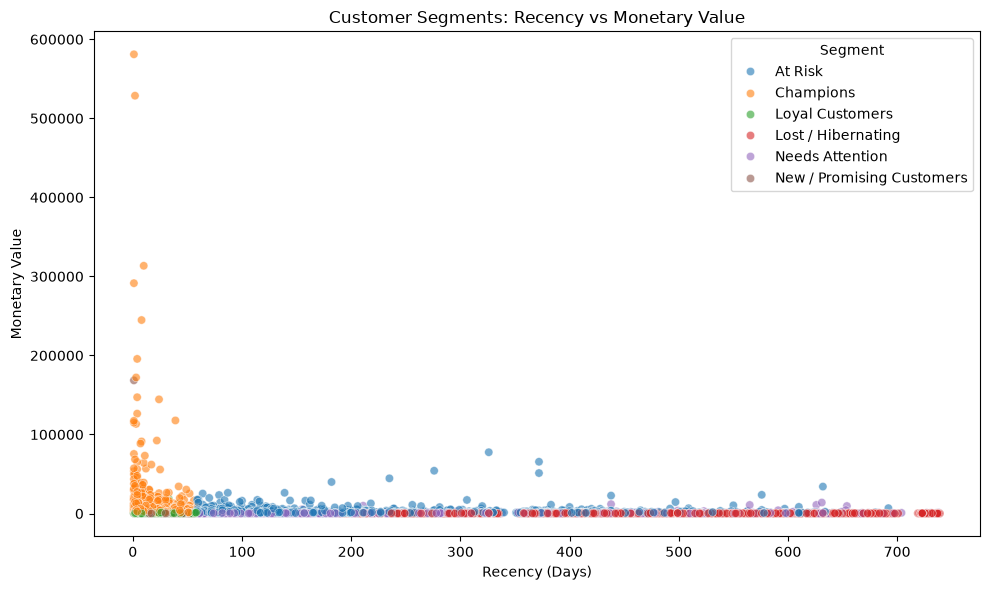

In [43]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm_score,
    x='Recency',
    y='Monetary',
    hue='Segment',
    alpha=0.6
)

plt.title('Customer Segments: Recency vs Monetary Value')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value')

plt.tight_layout()
plt.show()

In [44]:
rfm_score.to_parquet("../data/processed/customer_rfm_segments.parquet",index=False)

In [45]:
segment_profile.to_csv("../data/processed/customer_segment_profile.csv")

In [46]:
inertia = []
silhouette_scores = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    
    labels = kmeans.fit_predict(rfm_scaled)
    
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(rfm_scaled, labels))

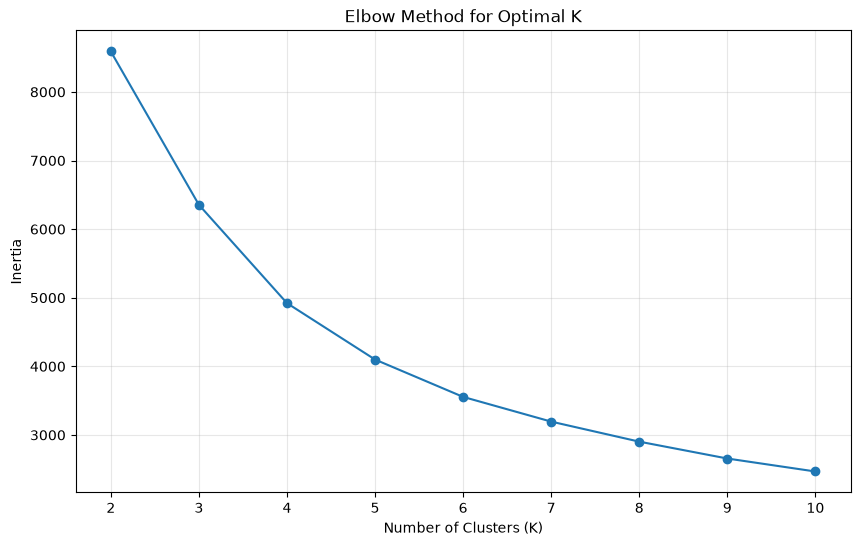

In [47]:
plt.figure(figsize=(10, 6))

plt.plot(list(K_range),inertia,marker='o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')

plt.xticks(list(K_range))
plt.grid(alpha=0.3)

plt.show()

In [48]:
cluster_evaluation = pd.DataFrame({
    'K': list(K_range),
    'Inertia': inertia,
    'Silhouette_Score': silhouette_scores
})

cluster_evaluation

,K,Inertia,Silhouette_Score
0,2,8588.985343,0.438602
1,3,6354.343153,0.347745
2,4,4921.233345,0.364971
3,5,4099.106079,0.342496
4,6,3554.696269,0.334796
5,7,3194.500972,0.306636
6,8,2902.433885,0.303315
7,9,2656.562328,0.292524
8,10,2467.378466,0.290525


## Selecting the Optimal Number of Clusters

The Elbow Method and Silhouette Score were evaluated for K values from 2 to 10.

The Elbow Method indicates that the rate of reduction in inertia begins to diminish around K = 4–5.

The highest Silhouette Score occurs at K = 2 (0.4386). However, K = 2 provides only two broad customer groups and is less useful for detailed customer profiling.

K = 4 provides a strong Silhouette Score of 0.3650 while remaining close to the elbow region. It therefore provides a reasonable balance between cluster separation, model simplicity, and business interpretability.

Based on these considerations, K = 4 is selected for the final K-Means customer segmentation.

In [49]:
final_k = 4

k_means_final = KMeans(n_clusters=final_k, random_state=42, n_init=10)

cluster_label = k_means_final.fit_predict(rfm_scaled)

In [50]:
rfm_clustered = rfm_raw.copy()

rfm_clustered["cluster"] = cluster_label

In [51]:
rfm_clustered['cluster'].value_counts().sort_index()

cluster
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64

In [52]:
cluster_profile = rfm_clustered.groupby('cluster').agg(
    Customers=('customer_id', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
)

cluster_profile['Customer_Percentage'] = (cluster_profile['Customers'] /len(rfm_clustered) * 100)

cluster_profile

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Percentage
cluster,,,,,
0,1973,394.946275,1.377598,317.081501,33.565839
1,1250,28.304800,3.053600,857.491434,21.265737
2,1196,27.711538,19.275920,10731.162991,20.347057
3,1459,230.072653,5.058259,1948.503933,24.821368


In [53]:
cluster_profile.sort_values('Avg_Monetary',ascending=False)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Percentage
cluster,,,,,
2,1196,27.711538,19.275920,10731.162991,20.347057
3,1459,230.072653,5.058259,1948.503933,24.821368
1,1250,28.304800,3.053600,857.491434,21.265737
0,1973,394.946275,1.377598,317.081501,33.565839


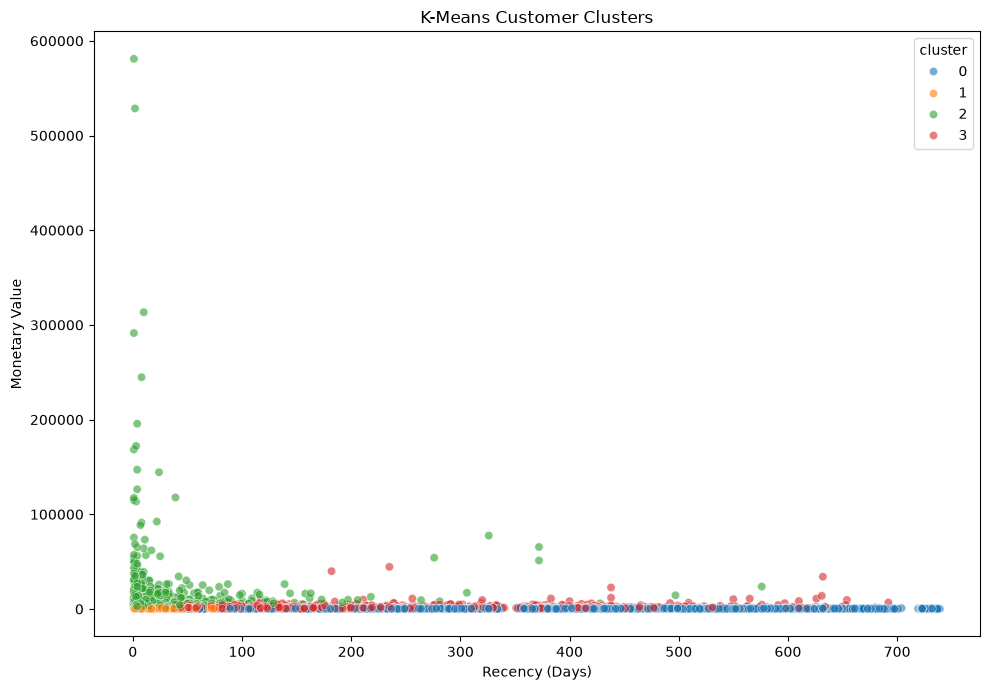

In [54]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=rfm_clustered,
    x='Recency',
    y='Monetary',
    hue='cluster',
    palette='tab10',
    alpha=0.6
)

plt.title('K-Means Customer Clusters')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value')

plt.tight_layout()
plt.show()

In [55]:
cluster_profile = rfm_clustered.groupby('cluster').agg(
    Customers=('customer_id', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Median_Recency=('Recency', 'median'),
    Median_Frequency=('Frequency', 'median'),
    Median_Monetary=('Monetary', 'median')
)

cluster_profile['Customer_Percentage'] = (
    cluster_profile['Customers'] / len(rfm_clustered) * 100
)

cluster_profile.sort_values('Avg_Monetary', ascending=False)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Recency,Median_Frequency,Median_Monetary,Customer_Percentage
cluster,,,,,,,,
2,1196,27.711538,19.275920,10731.162991,17.0,13.0,4986.115,20.347057
3,1459,230.072653,5.058259,1948.503933,186.0,4.0,1450.040,24.821368
1,1250,28.304800,3.053600,857.491434,24.0,3.0,734.115,21.265737
0,1973,394.946275,1.377598,317.081501,402.0,1.0,273.310,33.565839


In [56]:
cluster_names = {
    0: 'Lost / Hibernating',
    1: 'Loyal / Promising Customers',
    2: 'Champions',
    3: 'At Risk'
}

rfm_clustered['ML_Segment'] = (rfm_clustered['cluster'].map(cluster_names))

In [57]:
rfm_clustered[['customer_id', 'Recency', 'Frequency','Monetary', 'cluster', 'ML_Segment']].head(10)

,customer_id,Recency,Frequency,Monetary,cluster,ML_Segment
0,12346,326,12,77556.46,2,Champions
1,12347,2,8,4921.53,2,Champions
2,12348,75,5,2019.40,3,At Risk
3,12349,19,4,4428.69,1,Loyal / Promising Customers
4,12350,310,1,334.40,0,Lost / Hibernating
5,12351,375,1,300.93,0,Lost / Hibernating
6,12352,36,10,2849.84,2,Champions
7,12353,204,2,406.76,0,Lost / Hibernating
8,12354,232,1,1079.40,0,Lost / Hibernating
9,12355,214,2,947.61,3,At Risk


In [58]:
ml_segment_profile = rfm_clustered.groupby('ML_Segment').agg(
    Customers=('customer_id', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
)

ml_segment_profile['Customer_Percentage'] = (ml_segment_profile['Customers'] /len(rfm_clustered) * 100)

ml_segment_profile.sort_values('Avg_Monetary',ascending=False)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Percentage
ML_Segment,,,,,
Champions,1196,27.711538,19.275920,10731.162991,20.347057
At Risk,1459,230.072653,5.058259,1948.503933,24.821368
Loyal / Promising Customers,1250,28.304800,3.053600,857.491434,21.265737
Lost / Hibernating,1973,394.946275,1.377598,317.081501,33.565839


In [59]:
comparison = rfm_score[
    ['customer_id', 'Segment', 'RFM_Score']
].merge(
    rfm_clustered[
        ['customer_id', 'cluster', 'ML_Segment']
    ],
    on='customer_id',
    how='inner'
)

In [60]:
comparison.head()

,customer_id,Segment,RFM_Score,cluster,ML_Segment
0,12346,At Risk,12,2,Champions
1,12347,Champions,14,2,Champions
2,12348,At Risk,11,3,At Risk
3,12349,Loyal Customers,13,1,Loyal / Promising Customers
4,12350,Lost / Hibernating,5,0,Lost / Hibernating


In [61]:
segment_comparison = pd.crosstab(
    comparison['Segment'],
    comparison['ML_Segment']
)

segment_comparison

ML_Segment,At Risk,Champions,Lost / Hibernating,Loyal / Promising Customers
Segment,,,,
At Risk,1136,127,18,21
Champions,90,1061,0,138
Lost / Hibernating,0,0,1282,0
Loyal Customers,31,7,2,581
Needs Attention,202,0,632,109
New / Promising Customers,0,1,39,401


In [62]:
segment_comparison_pct = pd.crosstab(
    comparison['Segment'],
    comparison['ML_Segment'],
    normalize='index'
) * 100

segment_comparison_pct.round(2)

ML_Segment,At Risk,Champions,Lost / Hibernating,Loyal / Promising Customers
Segment,,,,
At Risk,87.25,9.75,1.38,1.61
Champions,6.98,82.31,0.00,10.71
Lost / Hibernating,0.00,0.00,100.00,0.00
Loyal Customers,4.99,1.13,0.32,93.56
Needs Attention,21.42,0.00,67.02,11.56
New / Promising Customers,0.00,0.23,8.84,90.93


## RFM vs K-Means Segmentation Comparison

The rule-based RFM segmentation and K-Means clustering show strong alignment despite being developed using different methodologies.

Key observations:

- 82.31% of RFM Champions were classified as Champions by K-Means.
- 93.56% of RFM Loyal Customers were classified as Loyal / Promising.
- 90.93% of RFM New / Promising Customers were classified as Loyal / Promising.
- 87.25% of RFM At Risk customers were classified as At Risk.
- 100% of RFM Lost / Hibernating customers were classified as Lost / Hibernating.
- The Needs Attention segment was distributed mainly between Lost / Hibernating (67.02%) and At Risk (21.42%), suggesting that this rule-based category does not represent a distinct natural cluster.

Overall, the dominant K-Means cluster corresponds to the RFM segment for approximately 86.6% of customers.

This provides evidence that the customer behavioral patterns identified through RFM scoring are also present in the unsupervised machine-learning segmentation.

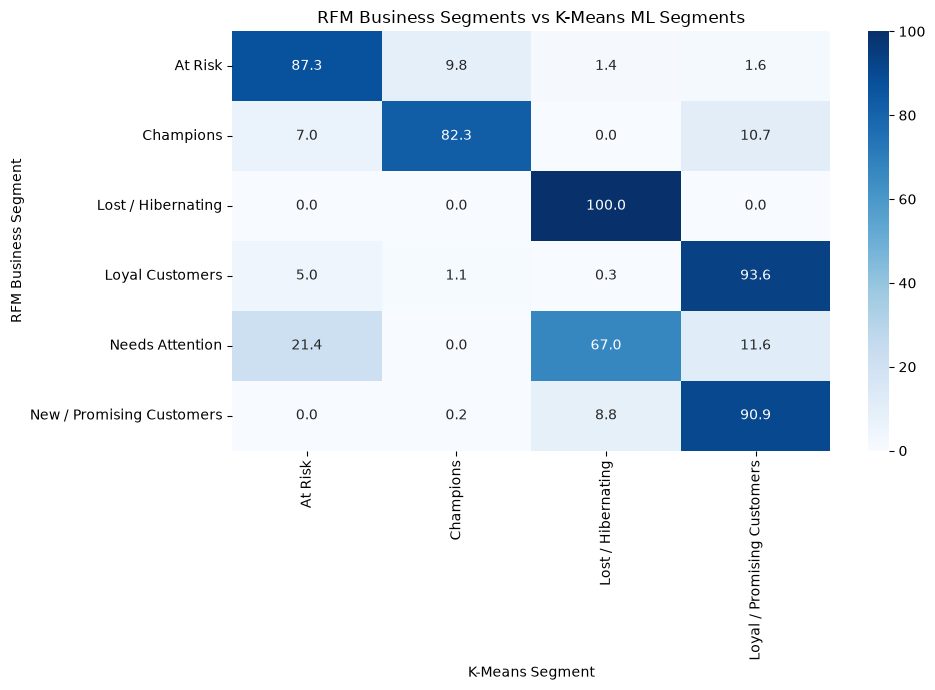

In [63]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    segment_comparison_pct,
    annot=True,
    fmt='.1f',
    cmap='Blues'
)

plt.title('RFM Business Segments vs K-Means ML Segments')

plt.xlabel('K-Means Segment')
plt.ylabel('RFM Business Segment')

plt.tight_layout()
plt.show()

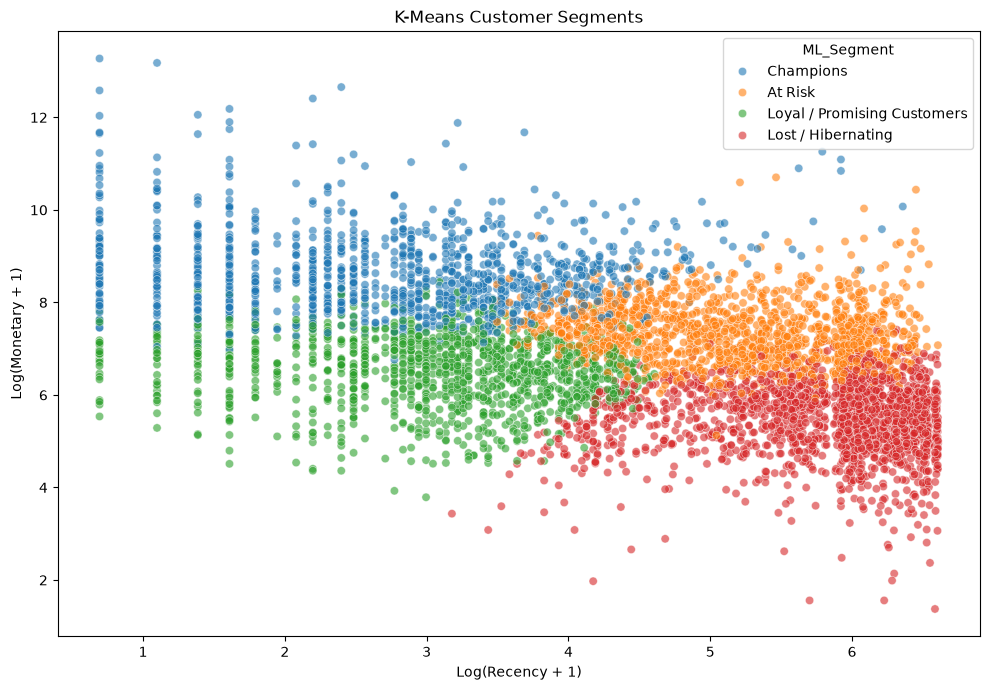

In [64]:
rfm_clustered_plot = rfm_clustered.copy()

rfm_clustered_plot['Log_Recency'] = np.log1p(rfm_clustered_plot['Recency'])

rfm_clustered_plot['Log_Monetary'] = np.log1p(rfm_clustered_plot['Monetary'])

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=rfm_clustered_plot,
    x='Log_Recency',
    y='Log_Monetary',
    hue='ML_Segment',
    alpha=0.6
)

plt.title('K-Means Customer Segments')
plt.xlabel('Log(Recency + 1)')
plt.ylabel('Log(Monetary + 1)')

plt.tight_layout()
plt.show()

In [65]:
rfm_clustered.to_parquet("../data/processed/customer_rfm_clusters.parquet",index=False)

In [66]:
ml_segment_profile.to_csv("../data/processed/ml_customer_segment_profile.csv")

In [67]:
segment_comparison.to_csv("../data/processed/rfm_kmeans_comparison.csv")

In [80]:
# Final K-Means model
final_k = 4

final_kmeans = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

final_labels = final_kmeans.fit_predict(rfm_scaled)

rfm_clustered['cluster'] = final_labels

In [82]:
rfm_clustered['cluster'].value_counts().sort_index()

cluster
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64

In [83]:
from sklearn.decomposition import PCA 

pca = PCA(n_components=2)

rfm_pca = pca.fit_transform(rfm_scaled)

rfm_pca_df = pd.DataFrame(
    rfm_pca,
    columns=['PC1', 'PC2'],
    index=rfm_clustered.index
)

rfm_pca_df['ML_Segment'] = rfm_clustered['ML_Segment'].values
rfm_pca_df['cluster'] = rfm_clustered['cluster'].values

In [84]:
pca.explained_variance_ratio_

array([0.76356725, 0.18744412])

In [85]:
print(f"PC1 explains {pca.explained_variance_ratio_[0] * 100:.2f}% of variance")

print(f"PC2 explains {pca.explained_variance_ratio_[1] * 100:.2f}% of variance")

print(f"Total explained variance: "f"{pca.explained_variance_ratio_.sum() * 100:.2f}%")

PC1 explains 76.36% of variance
PC2 explains 18.74% of variance
Total explained variance: 95.10%


In [86]:
cluster_centers_pca = pca.transform(final_kmeans.cluster_centers_)

print(cluster_centers_pca.shape)

(4, 2)


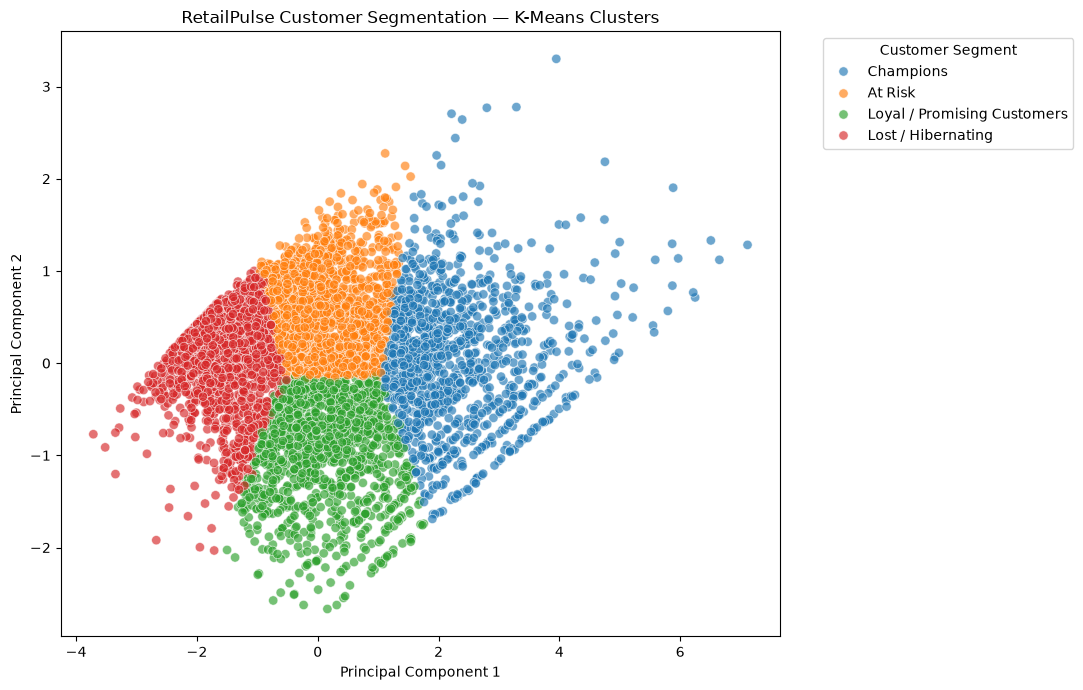

In [87]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=rfm_pca_df,
    x='PC1',
    y='PC2',
    hue='ML_Segment',
    alpha=0.65,
    s=45
)

plt.title('RetailPulse Customer Segmentation — K-Means Clusters')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Customer Segment',bbox_to_anchor=(1.05, 1),loc='upper left')

plt.tight_layout()
plt.show()

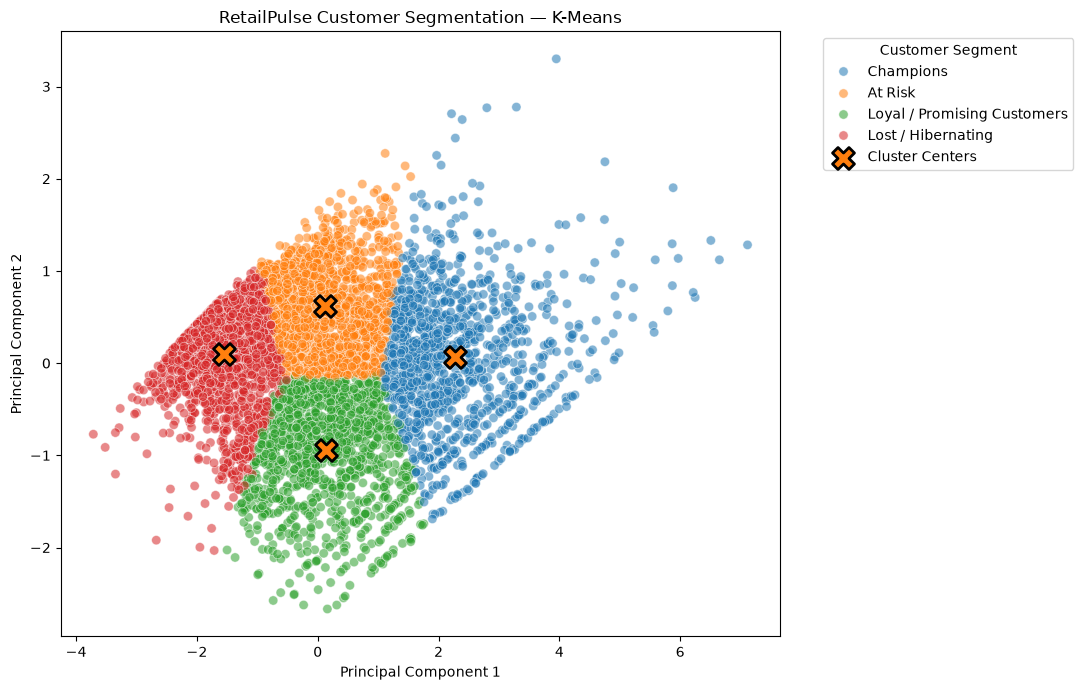

In [88]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=rfm_pca_df,
    x='PC1',
    y='PC2',
    hue='ML_Segment',
    alpha=0.55,
    s=45
)

plt.scatter(
    cluster_centers_pca[:, 0],
    cluster_centers_pca[:, 1],
    marker='X',
    s=250,
    edgecolor='black',
    linewidth=2,
    label='Cluster Centers'
)

plt.title('RetailPulse Customer Segmentation — K-Means')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.legend(title='Customer Segment',bbox_to_anchor=(1.05, 1),loc='upper left')

plt.tight_layout()
plt.show()

In [89]:
segment_size = (rfm_clustered['ML_Segment'].value_counts().reset_index())

segment_size.columns = ['ML_Segment', 'Customers']

segment_size['Percentage'] = (segment_size['Customers'] /len(rfm_clustered) * 100)

segment_size

,ML_Segment,Customers,Percentage
0,Lost / Hibernating,1973,33.565839
1,At Risk,1459,24.821368
2,Loyal / Promising Customers,1250,21.265737
3,Champions,1196,20.347057


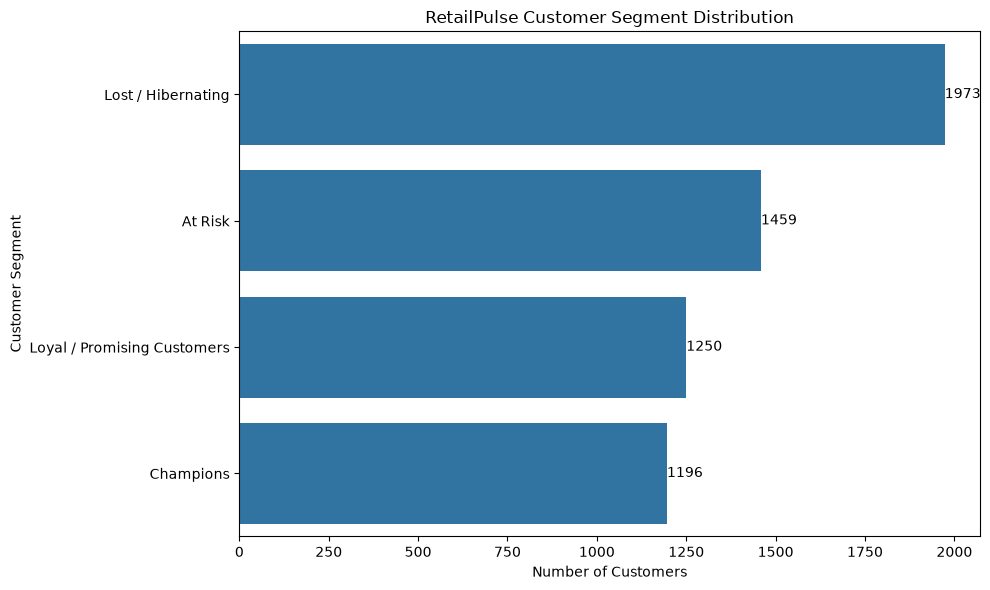

In [90]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(data=segment_size,x='Customers',y='ML_Segment')

plt.title('RetailPulse Customer Segment Distribution')
plt.xlabel('Number of Customers')
plt.ylabel('Customer Segment')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.tight_layout()
plt.show()

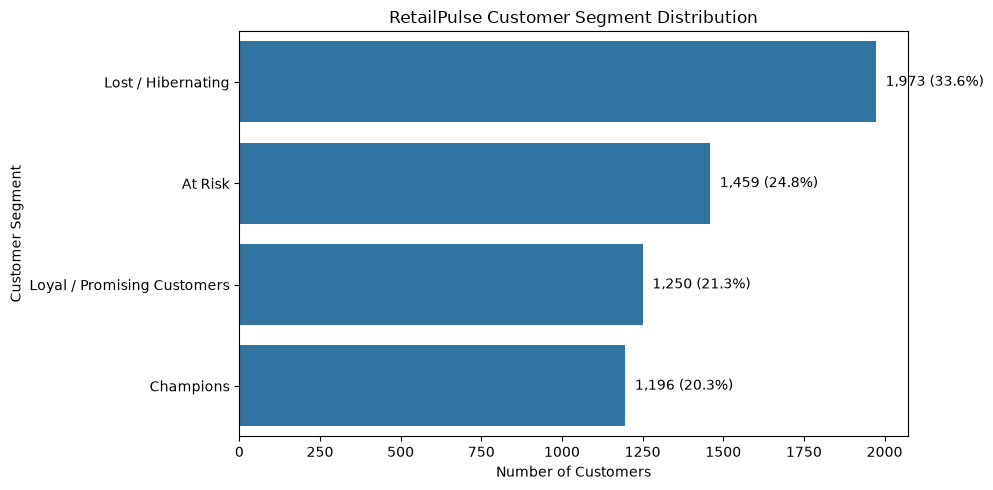

In [91]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(data=segment_size,x='Customers',y='ML_Segment')

plt.title('RetailPulse Customer Segment Distribution')
plt.xlabel('Number of Customers')
plt.ylabel('Customer Segment')

for i, row in segment_size.iterrows():
    ax.text(
        row['Customers'] + 30,
        i,
        f"{row['Customers']:,} ({row['Percentage']:.1f}%)",
        va='center'
    )

plt.tight_layout()
plt.show()

## K-Means Customer Segmentation Visualization

K-Means clustering was applied to the log-transformed and standardized RFM features. Four clusters were selected based on the Elbow Method, Silhouette Score, and business interpretability.

PCA was used to project the three-dimensional RFM feature space into two dimensions for visualization. The PCA plot provides a visual representation of the customer groups discovered by K-Means, while the cluster profiling provides the behavioral interpretation of each group.

In [92]:
final_cluster_profile = (
    rfm_clustered
    .groupby('ML_Segment')
    .agg(
        Customers=('customer_id', 'count'),
        Avg_Recency=('Recency', 'mean'),
        Avg_Frequency=('Frequency', 'mean'),
        Avg_Monetary=('Monetary', 'mean')
    )
)

final_cluster_profile['Customer_Percentage'] = (final_cluster_profile['Customers'] /len(rfm_clustered) * 100)

final_cluster_profile = final_cluster_profile.sort_values('Avg_Monetary', ascending=False)

final_cluster_profile.round(2)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Percentage
ML_Segment,,,,,
Champions,1196,27.71,19.28,10731.16,20.35
At Risk,1459,230.07,5.06,1948.50,24.82
Loyal / Promising Customers,1250,28.30,3.05,857.49,21.27
Lost / Hibernating,1973,394.95,1.38,317.08,33.57


## Business Interpretation of Customer Segments

The K-Means model identified four distinct customer behavior groups:

### Champions
Champions represent 20.35% of customers and have the highest purchasing activity and monetary value. Their average recency of approximately 28 days and average frequency of 19.28 purchases indicate strong and consistent engagement.

**Recommended actions:**
- VIP loyalty programs
- Personalized recommendations
- Cross-selling and upselling
- Early access to new products
- Exclusive rewards

### Loyal / Promising Customers
This segment represents 21.27% of customers. These customers have purchased recently but have lower purchase frequency and monetary value than Champions.

**Recommended actions:**
- Encourage repeat purchases
- Loyalty incentives
- Personalized offers
- Cross-selling
- Product recommendations

### At Risk
At Risk customers represent 24.82% of the customer base. They have relatively strong historical purchasing behavior but have not purchased recently, with an average recency of approximately 230 days.

**Recommended actions:**
- Win-back campaigns
- Personalized discounts
- Targeted email campaigns
- Product recommendations
- Limited-time reactivation offers

### Lost / Hibernating
Lost / Hibernating customers represent the largest segment at 33.57%. They have the highest average recency, lowest purchase frequency, and lowest monetary value.

**Recommended actions:**
- Low-cost reactivation campaigns
- Targeted promotional offers
- Reminder campaigns
- Evaluate customer acquisition cost before allocating significant marketing resources

# Key Findings

1. The dataset contains 5,878 unique customers for RFM-based segmentation.

2. K-Means clustering identified four customer behavior groups after applying log transformation and feature standardization.

3. K = 4 was selected based on the Elbow Method, Silhouette Score, and business interpretability.

4. Champions account for 20.35% of customers and have substantially higher purchase frequency and monetary value than the other segments.

5. Lost / Hibernating customers form the largest group, representing 33.57% of customers.

6. At Risk customers represent another 24.82% of the customer base and have meaningful historical purchasing value despite their low recent activity.

7. Combined, At Risk and Lost / Hibernating customers account for 58.39% of the customer base, highlighting a significant customer-retention and reactivation opportunity.

8. Comparison between rule-based RFM segmentation and K-Means showed strong alignment. The dominant K-Means cluster corresponded to the RFM segment for approximately 86.6% of customers.

9. The segmentation provides actionable customer groups that can be used for targeted retention, loyalty, reactivation, and marketing strategies.